# Tarea 04
---
### Generar una ANN del problema de Palmer Peguins
Se debe de utilizar la función de activación sigmoide con la función de Perdida Binary-Cross Entropy,
Generar un conjunto de entrenamiento al 80% y uno de test al 80%, reportar la matriz de confusión

In [1]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
from sklearn.preprocessing import StandardScaler
import numpy as np
import tensorflow as tf

In [2]:
from sklearn.model_selection import train_test_split

In [3]:
df = sns.load_dataset('penguins').dropna() # Elimina filas nulas

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 333 entries, 0 to 343
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            333 non-null    object 
 1   island             333 non-null    object 
 2   bill_length_mm     333 non-null    float64
 3   bill_depth_mm      333 non-null    float64
 4   flipper_length_mm  333 non-null    float64
 5   body_mass_g        333 non-null    float64
 6   sex                333 non-null    object 
dtypes: float64(4), object(3)
memory usage: 20.8+ KB


In [5]:
df.isna().sum() [df.isna().sum() > 0] / df.shape[0] * 100

,0


In [6]:
df.head(5)

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,Male
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,Female
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,Female
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,Female
5,Adelie,Torgersen,39.3,20.6,190.0,3650.0,Male


In [7]:
from sklearn.preprocessing import LabelEncoder

numerical_columns = [
    "bill_length_mm", "bill_depth_mm",
    "flipper_length_mm", "body_mass_g"
]

### Combinaciones
1. Sin Adelie
2. Sin Chinstrap
3. Sin Gentoo

### 1. Sin Adelie

In [8]:
par = ["Chinstrap", "Gentoo"]
d = df[df["species"].isin(par)].copy()
X = d[numerical_columns].reset_index(drop=True)
y = (d["species"] == "Gentoo").astype(int).values


In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=20261025
)
X_train = X_train.reset_index(drop=True)
X_test = X_test.reset_index(drop=True)

In [10]:
for n in numerical_columns:
    scaler = StandardScaler().fit(X_train[[n]])
    X_train[n] = scaler.transform(X_train[[n]])
    X_test[n] = scaler.transform(X_test[[n]])

In [11]:
tf.keras.utils.set_random_seed(20261025)
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(X_train.shape[1],)),
    tf.keras.layers.Dense(units=1, activation="sigmoid"),
])

In [12]:
model.compile(
    loss="binary_crossentropy",
    optimizer=tf.keras.optimizers.SGD(learning_rate=0.1),
    metrics=["accuracy"],
)

In [13]:
model.fit(X_train, y_train, epochs=1000, verbose=0)

In [14]:
y_pred = (model.predict(X_test, verbose=0) > 0.5).astype(int).ravel()

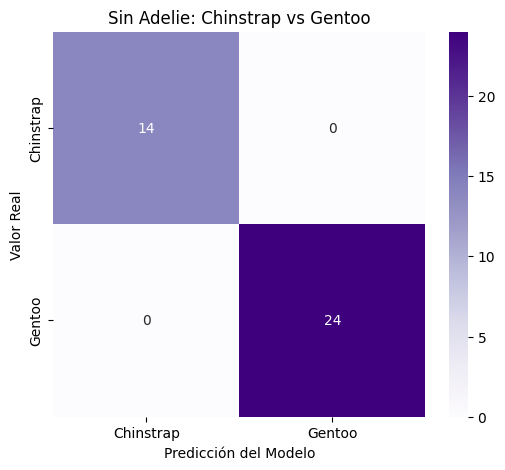

In [15]:
cm = tf.math.confusion_matrix(labels=y_test, predictions=y_pred).numpy()

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Purples", xticklabels=par, yticklabels=par)
plt.xlabel("Predicción del Modelo")
plt.ylabel("Valor Real")
plt.title("Sin Adelie: Chinstrap vs Gentoo")
plt.show()

### 2. Sin Chinstrap

In [16]:
par = ["Adelie", "Gentoo"]
d = df[df["species"].isin(par)].copy()
X = d[numerical_columns].reset_index(drop=True)
y = (d["species"] == "Gentoo").astype(int).values

In [17]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=20261025
)
X_train = X_train.reset_index(drop=True)
X_test = X_test.reset_index(drop=True)

In [18]:
for n in numerical_columns:
    scaler = StandardScaler().fit(X_train[[n]])
    X_train[n] = scaler.transform(X_train[[n]])
    X_test[n] = scaler.transform(X_test[[n]])

In [19]:
tf.keras.utils.set_random_seed(20261025)
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(X_train.shape[1],)),
    tf.keras.layers.Dense(units=1, activation="sigmoid"),
])

In [20]:
model.compile(
    loss="binary_crossentropy",
    optimizer=tf.keras.optimizers.SGD(learning_rate=0.1),
    metrics=["accuracy"],
)

In [21]:
model.fit(X_train, y_train, epochs=1000, verbose=0)

In [22]:
y_pred = (model.predict(X_test, verbose=0) > 0.5).astype(int).ravel()

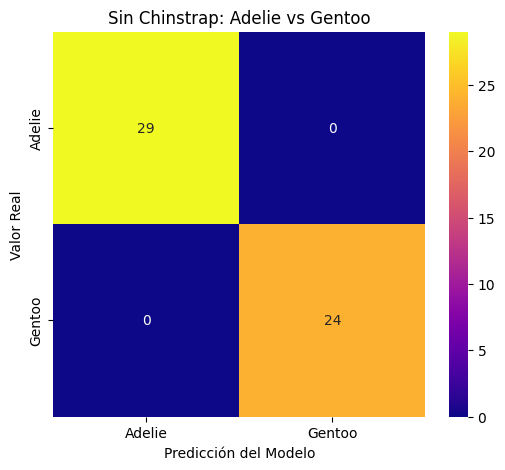

In [23]:
cm = tf.math.confusion_matrix(labels=y_test, predictions=y_pred).numpy()

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="plasma", xticklabels=par, yticklabels=par)
plt.xlabel("Predicción del Modelo")
plt.ylabel("Valor Real")
plt.title("Sin Chinstrap: Adelie vs Gentoo")
plt.show()

### Sin Gentoo

In [24]:
par = ["Adelie", "Chinstrap"]
d = df[df["species"].isin(par)].copy()
X = d[numerical_columns].reset_index(drop=True)
y = (d["species"] == "Chinstrap").astype(int).values

In [25]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=20261025
)
X_train = X_train.reset_index(drop=True)
X_test = X_test.reset_index(drop=True)

In [26]:
for n in numerical_columns:
    scaler = StandardScaler().fit(X_train[[n]])
    X_train[n] = scaler.transform(X_train[[n]])
    X_test[n] = scaler.transform(X_test[[n]])

In [27]:
tf.keras.utils.set_random_seed(20261025)
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(X_train.shape[1],)),
    tf.keras.layers.Dense(units=1, activation="sigmoid"),
])

In [28]:
model.compile(
    loss="binary_crossentropy",
    optimizer=tf.keras.optimizers.SGD(learning_rate=0.1),
    metrics=["accuracy"],
)

In [29]:
model.fit(X_train, y_train, epochs=1000, verbose=0)

In [30]:
y_pred = (model.predict(X_test, verbose=0) > 0.5).astype(int).ravel()

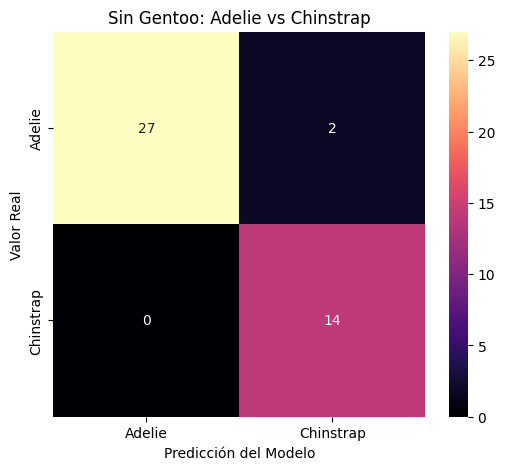

In [31]:
cm = tf.math.confusion_matrix(labels=y_test, predictions=y_pred).numpy()

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="magma", xticklabels=par, yticklabels=par)
plt.xlabel("Predicción del Modelo")
plt.ylabel("Valor Real")
plt.title("Sin Gentoo: Adelie vs Chinstrap")
plt.show()